# 05 · Coverage proxies at tract level

How complete does Overture look, tract by tract, and how does that vary with urbanity, vulnerability and tribal status? Box plots, heatmaps, formal tests with effect sizes, and a diagnosed regression. Reads the committed `analysis_outputs/` tables.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "analysis_outputs").exists())
OUT = ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})

REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))

# one table: Overture aggregates + ACS + strata, one row per scored tract (built by the earlier notebooks)
df = pd.read_parquet(OUT / "tract_analysis_table.parquet")
df["land_km2"] = df.ALAND / 1e6

def box_by_region(ax, col, data=None, log=False, title="", ylabel=None):
    """Box plot of one column for each region (log10 if log=True), n shown under each box."""
    d = df if data is None else data
    vals = [d.loc[d.region == r, col].dropna() for r in REG]
    if log: vals = [np.log10(v[v > 0]) for v in vals]
    bp = ax.boxplot(vals, patch_artist=True, medianprops=dict(color="k"), flierprops=dict(marker=".", markersize=2, alpha=.3))
    for patch, r in zip(bp["boxes"], REG): patch.set_facecolor(COL[r]); patch.set_alpha(.75)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([f"{NAME[r]}\nn={len(v):,}" for r, v in zip(REG, vals)], fontsize=7.5)
    ax.set_title(title); ax.set_ylabel(ylabel or (("log10 " if log else "") + col))

def n_outliers(s):
    """Number of values outside the 1.5 x IQR fences."""
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return int(((s < q1 - k) | (s > q3 + k)).sum())

def heat(ax, M, fmt="{:.2f}", cmap="RdBu_r", vmin=-1, vmax=1, fs=7, rot=60):
    """Annotated heatmap of a DataFrame."""
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=rot, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs, color="k" if abs(v - (vmin + vmax) / 2) < (vmax - vmin) * .35 else "w")
    return im

## 1. How often is a feature missing from Overture altogether?

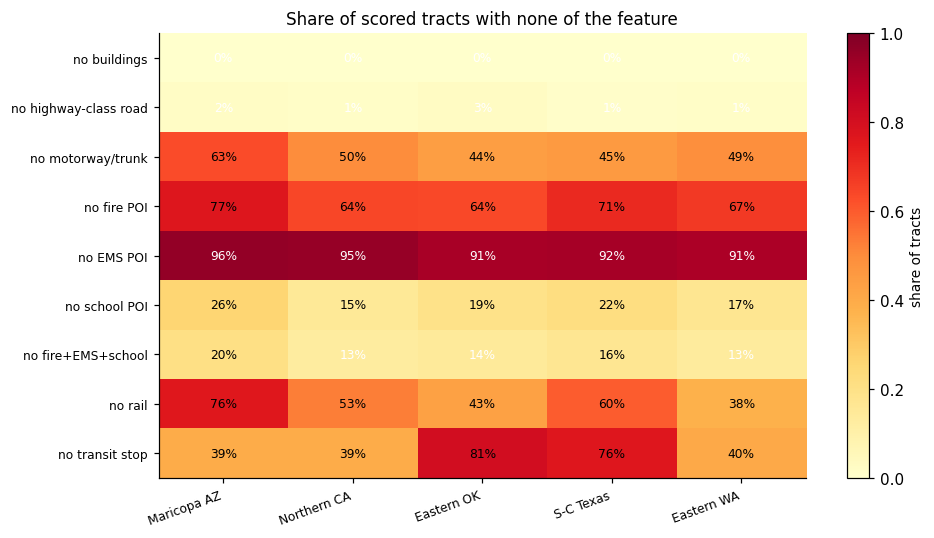

In [2]:
rules = {"no buildings": lambda d: d.bldg_n == 0, "no highway-class road": lambda d: d.road_km_hwy < .01, "no motorway/trunk": lambda d: (d.road_km_motorway + d.road_km_trunk) < .01,
         "no fire POI": lambda d: d.poi_n_fire == 0, "no EMS POI": lambda d: d.poi_n_ems == 0, "no school POI": lambda d: d.poi_n_school == 0,
         "no fire+EMS+school": lambda d: (d.poi_n_fire + d.poi_n_ems + d.poi_n_school) == 0, "no rail": lambda d: d.rail_km == 0, "no transit stop": lambda d: d.infra_n_transit == 0}
Z = pd.DataFrame({k: df.groupby("region").apply(lambda d, f=f: f(d).mean()) for k, f in rules.items()}).reindex(REG).T; Z.columns = [NAME[r] for r in REG]
fig, ax = plt.subplots(figsize=(9, 5)); plt.colorbar(heat(ax, Z, fmt="{:.0%}", cmap="YlOrRd", vmin=0, vmax=1, fs=8, rot=20), ax=ax, label="share of tracts"); ax.set_title("Share of scored tracts with none of the feature")
plt.tight_layout(); plt.show()

**Takeaway:** nearly every tract has buildings and a highway-class road, but 64-77% have no fire POI and 91-96% no EMS POI, and Oklahoma and Texas have no transit stop in about 80% of tracts. Facility presence is the exception, which makes facility-based gaps lumpy.

## 2. Building counts against independent counts (a gap needs ratio < 1)

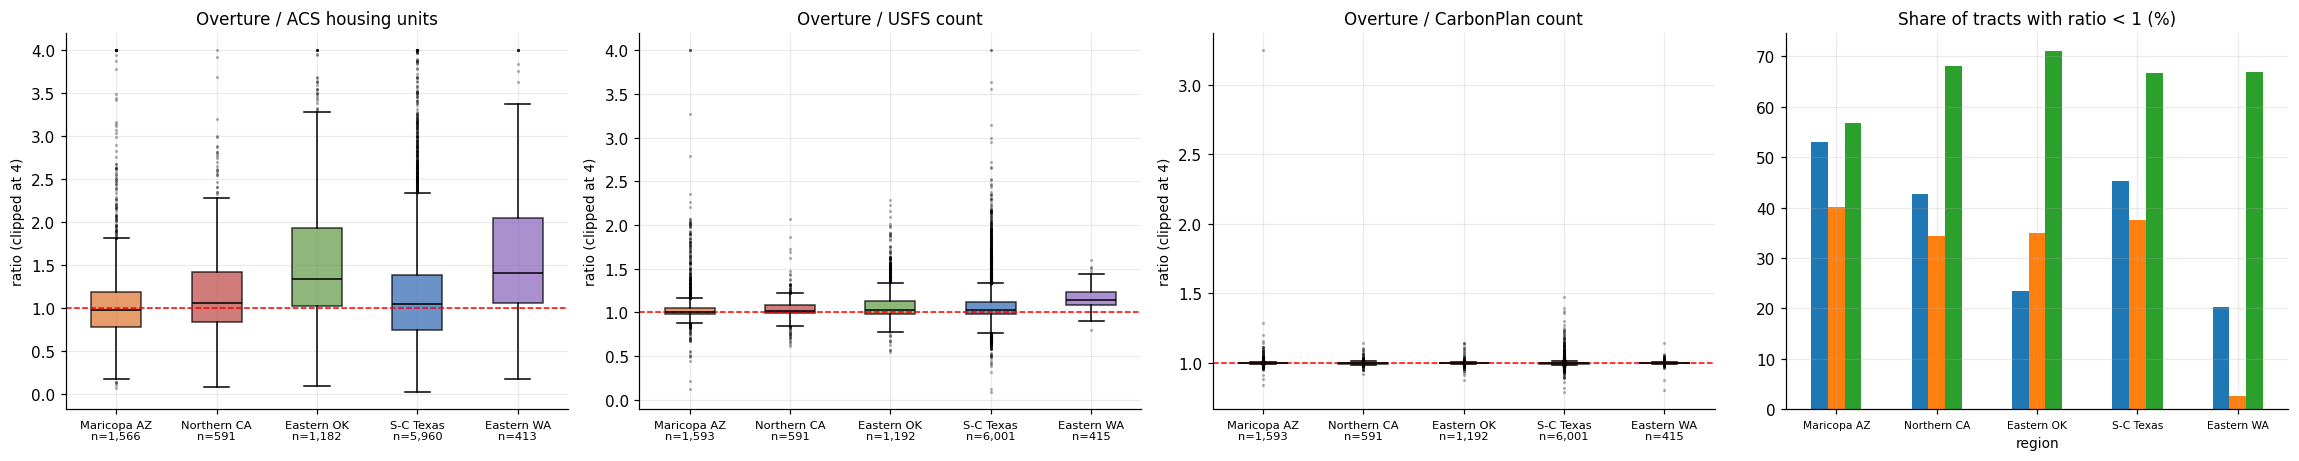

                  Overture / ACS housing units  Overture / USFS count  Overture / CarbonPlan count
region                                                                                            
maricopa-az                               53.0                   40.0                         57.0
northern-ca                               43.0                   34.0                         68.0
eastern-ok                                24.0                   35.0                         71.0
south-central-tx                          45.0                   37.0                         67.0
eastern-wa                                20.0                    3.0                         67.0


In [3]:
R = {"ratio_bldg_housing_units": "Overture / ACS housing units", "ratio_bldg_usfs_BuildingCount_sum": "Overture / USFS count", "ratio_bldg_carbonplan_buildings": "Overture / CarbonPlan count"}
fig, ax = plt.subplots(1, 4, figsize=(21, 4.3))
for a, (c, t) in zip(ax, R.items()):
    box_by_region(a, c, data=df.assign(**{c: df[c].replace(np.inf, np.nan).clip(upper=4)}), title=t, ylabel="ratio (clipped at 4)"); a.axhline(1, color="r", ls="--", lw=1)
sh = pd.DataFrame({t: df.groupby("region")[c].apply(lambda s: (s.replace(np.inf, np.nan).dropna() < 1).mean()) for c, t in R.items()}).reindex(REG)
(sh * 100).plot.bar(ax=ax[3], rot=0, legend=False); ax[3].set_title("Share of tracts with ratio < 1 (%)"); ax[3].set_xticklabels([NAME[r] for r in REG], fontsize=7)
plt.tight_layout(); plt.show(); print((sh * 100).round(0).to_string())

**Takeaway:** against housing units the ratio is wide and above 1 in rural regions (outbuildings). Against USFS it sits just above 1, and against CarbonPlan it is essentially 1. A building gap can only appear where the ratio is below 1: that is 36% of tracts overall for USFS (3% in Eastern WA to 40% in Maricopa) and 20-53% against housing units. The tall CarbonPlan bars are a trap: its ratio is 0.998, so it is below 1 by 0.2%, which is release noise and not a gap.

## 3. Coverage proxies by stratum

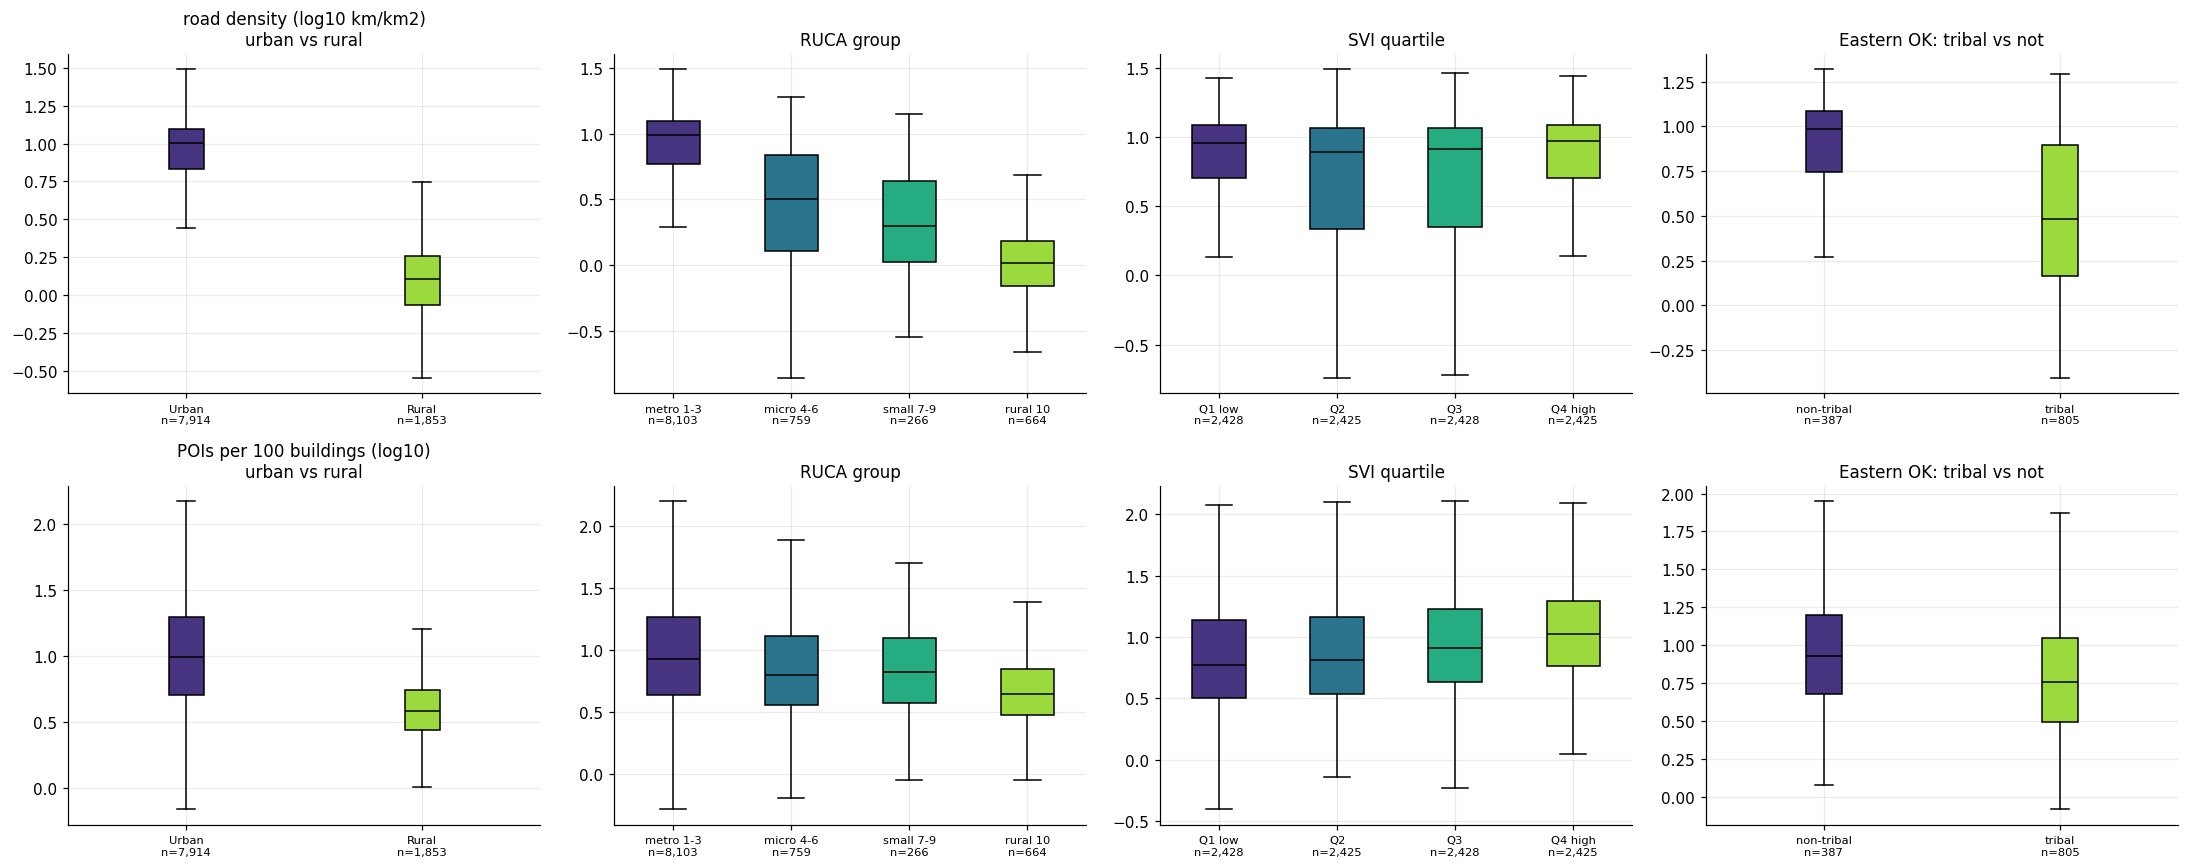

          road_km_per_km2  poi_per_100_bldg
ur_class                                   
Rural                1.27              3.84
Urban               10.03              9.78
            road_km_per_km2  poi_per_100_bldg
grp                                          
non-tribal             9.62              8.50
tribal                 3.04              5.74


In [4]:
def group_box(ax, col, by, order, title, data=df, log=True):
    v = [data.loc[data[by] == g, col].dropna() for g in order]; v = [np.log10(x[x > 0]) for x in v] if log else v
    bp = ax.boxplot(v, patch_artist=True, showfliers=False, medianprops=dict(color="k"))
    for p, c in zip(bp["boxes"], plt.cm.viridis(np.linspace(.15, .85, len(order)))): p.set_facecolor(c)
    ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels([f"{g}\nn={len(x):,}" for g, x in zip(order, v)], fontsize=7.5); ax.set_title(title)
ok = df[df.region == "eastern-ok"].assign(grp=lambda d: np.where(d.tribal, "tribal", "non-tribal"))
fig, ax = plt.subplots(2, 4, figsize=(20, 8))
for r, (col, nm) in enumerate([("road_km_per_km2", "road density (log10 km/km2)"), ("poi_per_100_bldg", "POIs per 100 buildings (log10)")]):
    group_box(ax[r, 0], col, "ur_class", ["Urban", "Rural"], f"{nm}\nurban vs rural"); group_box(ax[r, 1], col, "ruca_grp", ["metro 1-3", "micro 4-6", "small 7-9", "rural 10"], "RUCA group")
    group_box(ax[r, 2], col, "svi_q", ["Q1 low", "Q2", "Q3", "Q4 high"], "SVI quartile"); group_box(ax[r, 3], col, "grp", ["non-tribal", "tribal"], "Eastern OK: tribal vs not", data=ok)
plt.tight_layout(); plt.show()
print(df.groupby("ur_class")[["road_km_per_km2", "poi_per_100_bldg"]].median().round(2).to_string()); print(ok.groupby("grp")[["road_km_per_km2", "poi_per_100_bldg"]].median().round(2).to_string())

**Takeaway:** median road density is 10.0 km/km2 in urban tracts vs 1.3 in rural ones, and POIs per 100 buildings are 9.8 vs 3.8. Across SVI quartiles road density differs but not in a straight line. In Eastern Oklahoma tribal tracts are lower on both (road density 3.0 vs 9.6, POIs 5.7 vs 8.5), but they are also much more rural, so this is confounded with rurality.

## 4. Formal tests with effect sizes

Eastern OK, log10 POIs/100 buildings, tribal vs non-tribal:
  Welch t = -6.9 (p = 1.1e-11) | Mann-Whitney p = 2.1e-11 | Cohen's d = -0.44 | difference -0.19, 95% CI [-0.25, -0.14]
Point-biserial, fire POI present vs log population: 0.032 | vs log area: 0.333
Phi, tribal x no-fire-POI: -0.093


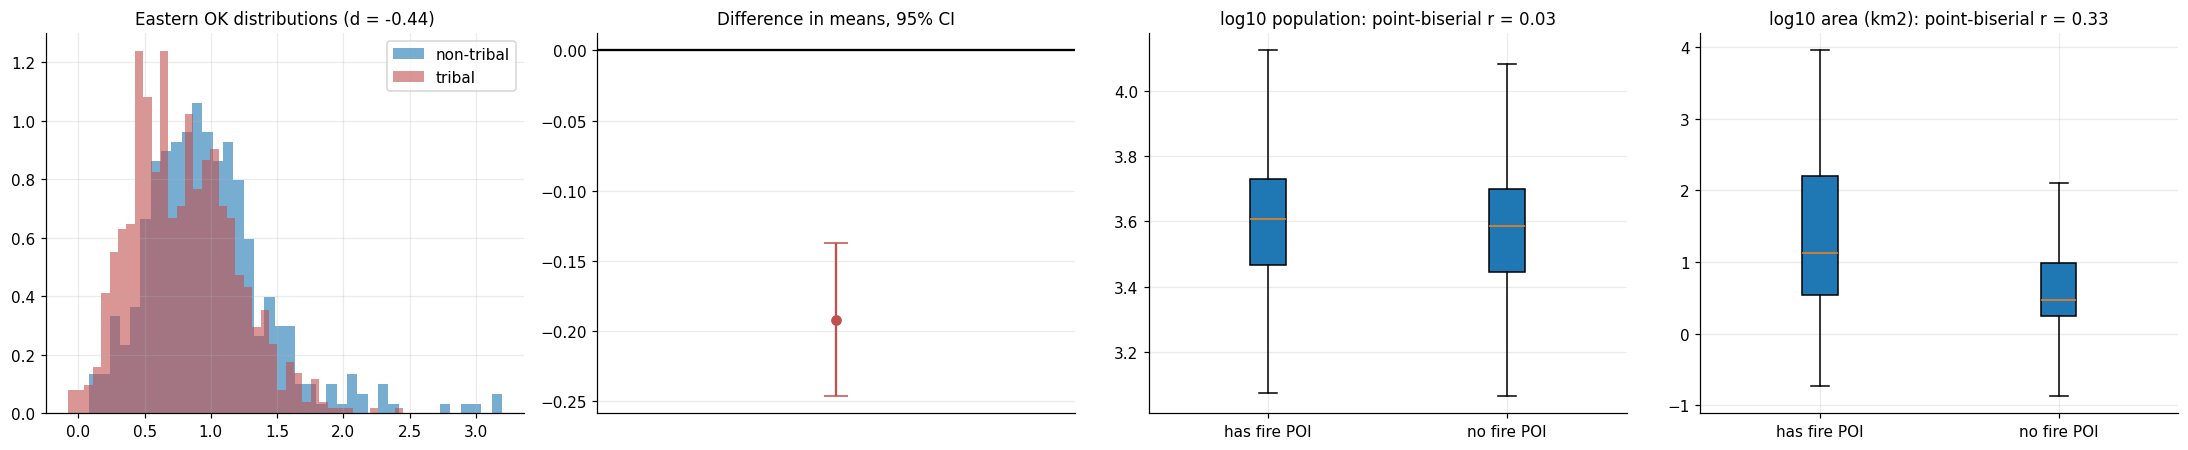

In [5]:
a = np.log10(ok[ok.tribal].poi_per_100_bldg.clip(lower=1e-3)); b = np.log10(ok[~ok.tribal].poi_per_100_bldg.clip(lower=1e-3))
t, p_t = stats.ttest_ind(a, b, equal_var=False); u, p_u = stats.mannwhitneyu(a, b); d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
se = np.sqrt(a.var() / len(a) + b.var() / len(b)); diff = a.mean() - b.mean(); ci = diff + np.array([-1, 1]) * 1.96 * se
pb_pop = stats.pointbiserialr((df.poi_n_fire > 0).astype(int), np.log10(df.pop_total.clip(lower=1)))[0]; pb_area = stats.pointbiserialr((df.poi_n_fire > 0).astype(int), np.log10(df.tract_area_km2.clip(lower=.01)))[0]
ct = pd.crosstab(df.tribal, df.poi_n_fire == 0); phi = (ct.iloc[0, 0] * ct.iloc[1, 1] - ct.iloc[0, 1] * ct.iloc[1, 0]) / np.sqrt(ct.sum(1).prod() * ct.sum(0).prod())
print(f"Eastern OK, log10 POIs/100 buildings, tribal vs non-tribal:\n  Welch t = {t:.1f} (p = {p_t:.1e}) | Mann-Whitney p = {p_u:.1e} | Cohen's d = {d:.2f} | difference {diff:.2f}, 95% CI [{ci[0]:.2f}, {ci[1]:.2f}]")
print(f"Point-biserial, fire POI present vs log population: {pb_pop:.3f} | vs log area: {pb_area:.3f}\nPhi, tribal x no-fire-POI: {phi:.3f}")
fire = df.poi_n_fire > 0
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
ax[0].hist(b, bins=40, alpha=.6, density=True, label="non-tribal"); ax[0].hist(a, bins=40, alpha=.6, density=True, color="#c0504d", label="tribal"); ax[0].legend(); ax[0].set_title(f"Eastern OK distributions (d = {d:.2f})")
ax[1].errorbar([0], [diff], yerr=[[diff - ci[0]], [ci[1] - diff]], fmt="o", capsize=8, color="#c0504d"); ax[1].axhline(0, color="k"); ax[1].set_xlim(-1, 1); ax[1].set_xticks([]); ax[1].set_title("Difference in means, 95% CI")
for a_, col, nm, rr in [(ax[2], "pop_total", "log10 population", pb_pop), (ax[3], "tract_area_km2", "log10 area (km2)", pb_area)]:
    a_.boxplot([np.log10(df.loc[fire, col].clip(lower=.01)), np.log10(df.loc[~fire, col].clip(lower=.01))], patch_artist=True, showfliers=False); a_.set_xticks([1, 2]); a_.set_xticklabels(["has fire POI", "no fire POI"]); a_.set_title(f"{nm}: point-biserial r = {rr:.2f}")
plt.tight_layout(); plt.show()

**Takeaway:** the t-test and the rank-based Mann-Whitney test agree (p about 1e-11) and Cohen's d = -0.44 is a small-to-medium effect. Having a fire POI depends on tract *area* (r = 0.33) and barely on population (r = 0.03): large tracts simply contain more places. The tribal x no-fire phi of -0.09 is a weak association.

## 5. Correlation structure of the proxies

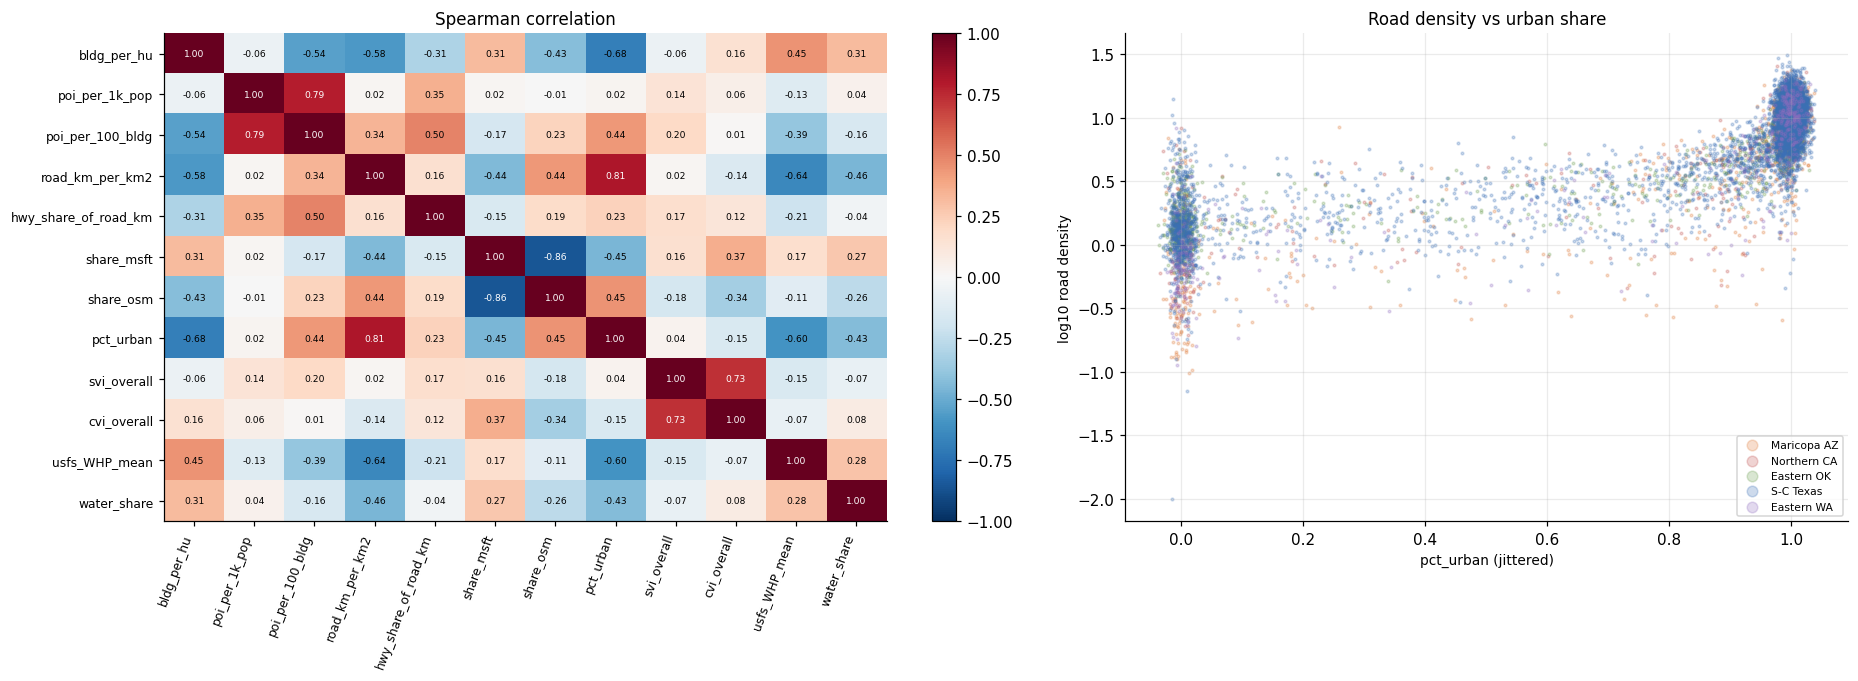

            road_km_per_km2  share_osm  pct_urban
pct_urban              0.81       0.45       1.00
share_msft            -0.44      -0.86      -0.45


In [6]:
cols = ["bldg_per_hu", "poi_per_1k_pop", "poi_per_100_bldg", "road_km_per_km2", "hwy_share_of_road_km", "share_msft", "share_osm", "pct_urban", "svi_overall", "cvi_overall", "usfs_WHP_mean", "water_share"]
cm = df[cols].replace(np.inf, np.nan).corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(17, 6.3), gridspec_kw={"width_ratios": [1.25, 1]})
plt.colorbar(heat(ax[0], cm, fs=6, rot=70), ax=ax[0]); ax[0].set_title("Spearman correlation")
for r in REG:
    d_ = df[df.region == r]; ax[1].scatter(d_.pct_urban + np.random.default_rng(0).normal(0, .012, len(d_)), np.log10(d_.road_km_per_km2.clip(lower=.01)), s=3, alpha=.25, color=COL[r], label=NAME[r])
ax[1].set(xlabel="pct_urban (jittered)", ylabel="log10 road density", title="Road density vs urban share"); ax[1].legend(markerscale=4, fontsize=7)
plt.tight_layout(); plt.show(); print(cm.loc[["pct_urban", "share_msft"], ["road_km_per_km2", "share_osm", "pct_urban"]].round(2).to_string())

**Takeaway:** road density is the strongest urbanity signal (Spearman +0.81 with `pct_urban`), the Microsoft share rises as tracts get more rural (-0.45 with `pct_urban`), and OSM and Microsoft shares are strongly negatively related (-0.86), meaning they substitute for each other. `pct_urban` is almost binary, so road density is the more informative urbanity measure.

## 6. Regression with diagnostics
Outcome: log POIs per 100 buildings. Checked for significance, multicollinearity (VIF), residual behaviour and influential tracts.

n = 9706 | R2 = 0.210 | F = 234 (p = 0.0e+00)
             coef per SD       t      p     VIF
pct_urban          0.215  10.857  0.000   4.113
road_dens          0.244   8.871  0.000   7.937
pop_dens          -0.082  -2.612  0.009  10.242
svi_overall        0.301  20.181  0.000   2.203
cvi_overall       -0.170 -10.787  0.000   2.355
share_msft        -0.062  -5.041  0.000   1.416
water_share       -0.015  -1.539  0.124   1.016


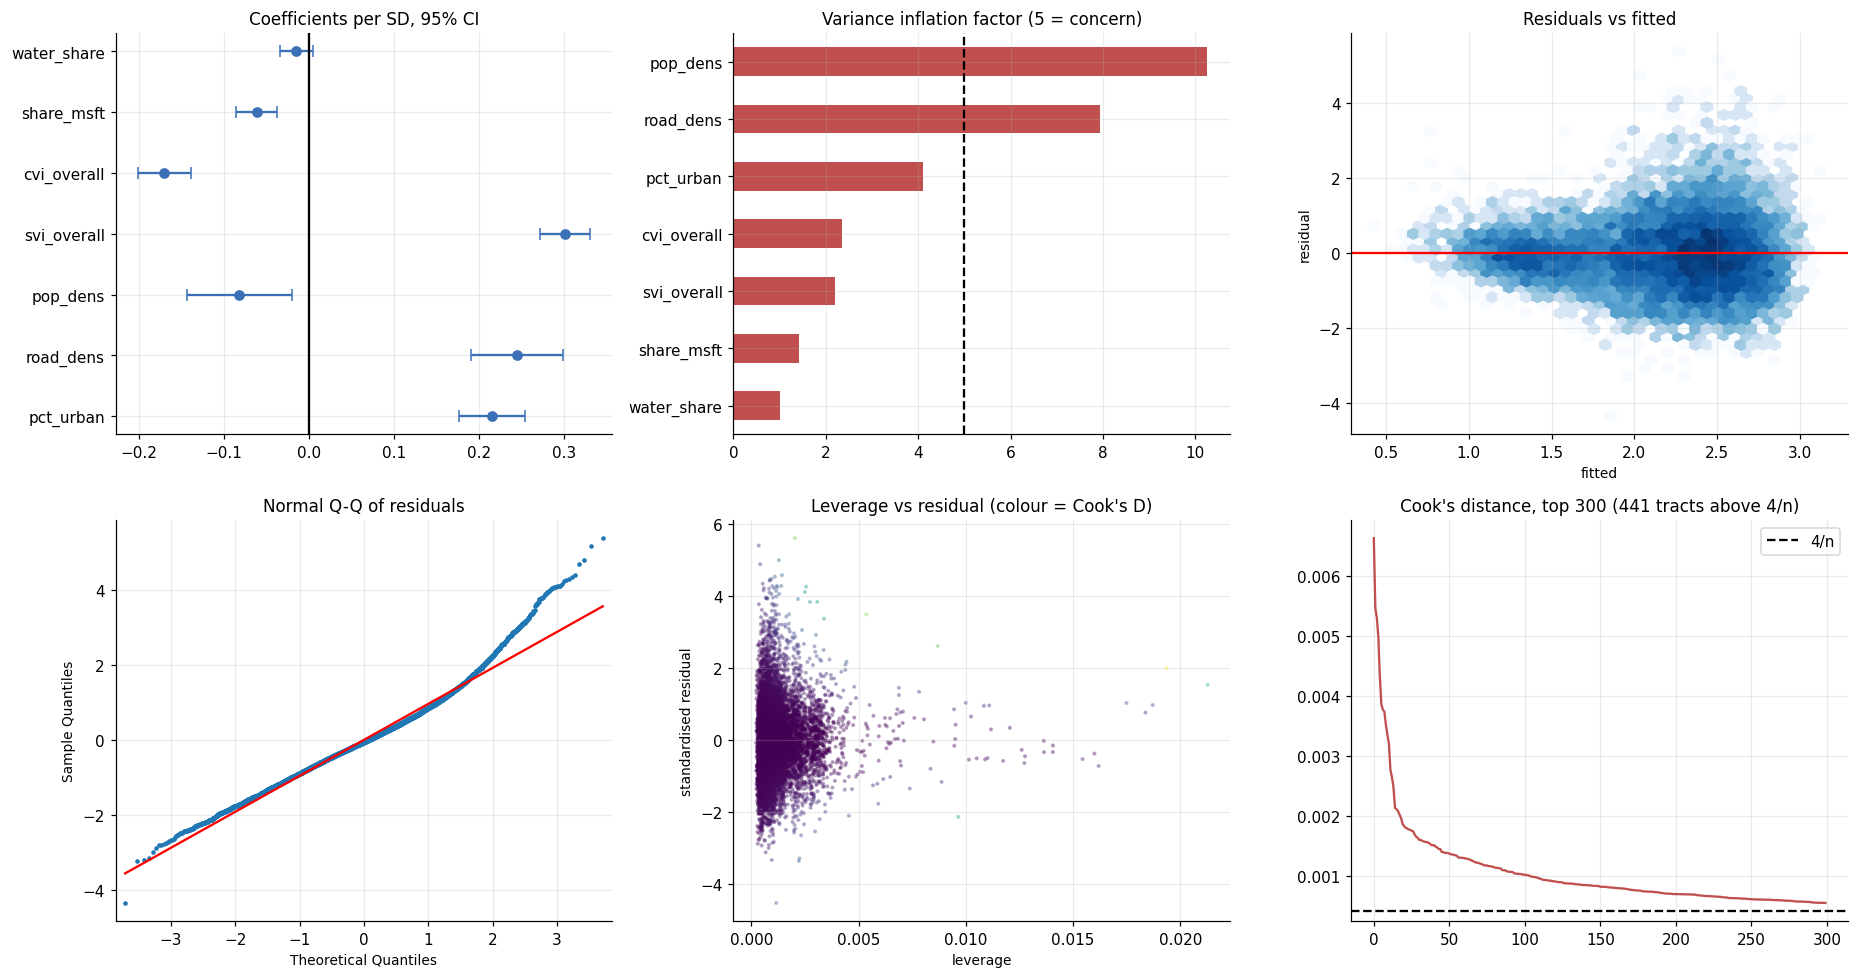

In [7]:
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
Rg = df.replace([np.inf, -np.inf], np.nan).copy(); Rg["y"] = np.log(Rg.poi_per_100_bldg.replace(0, np.nan)); Rg["road_dens"] = np.log1p(Rg.road_km_per_km2); Rg["pop_dens"] = np.log1p(Rg.pop_total / Rg.land_km2.replace(0, np.nan))
xs = ["pct_urban", "road_dens", "pop_dens", "svi_overall", "cvi_overall", "share_msft", "water_share"]
Rg = Rg.dropna(subset=["y"] + xs); Rg[xs] = (Rg[xs] - Rg[xs].mean()) / Rg[xs].std()
m = smf.ols("y ~ " + " + ".join(xs) + " + C(region)", Rg).fit(); vif = pd.Series([variance_inflation_factor(sm.add_constant(Rg[xs]).values, i + 1) for i in range(len(xs))], xs)
inf = m.get_influence(); cook = inf.cooks_distance[0]
print(f"n = {int(m.nobs)} | R2 = {m.rsquared:.3f} | F = {m.fvalue:.0f} (p = {m.f_pvalue:.1e})"); print(pd.DataFrame({"coef per SD": m.params[xs], "t": m.tvalues[xs], "p": m.pvalues[xs], "VIF": vif}).round(3).to_string())
fig, ax = plt.subplots(2, 3, figsize=(17, 9)); ci = m.conf_int().loc[xs]
ax[0, 0].errorbar(m.params[xs], range(len(xs)), xerr=[m.params[xs] - ci[0], ci[1] - m.params[xs]], fmt="o", capsize=4, color="#3b6fb6"); ax[0, 0].axvline(0, color="k"); ax[0, 0].set_yticks(range(len(xs))); ax[0, 0].set_yticklabels(xs); ax[0, 0].set_title("Coefficients per SD, 95% CI")
vif.sort_values().plot.barh(ax=ax[0, 1], color="#c0504d"); ax[0, 1].axvline(5, color="k", ls="--"); ax[0, 1].set_title("Variance inflation factor (5 = concern)")
ax[0, 2].hexbin(m.fittedvalues, m.resid, gridsize=40, cmap="Blues", mincnt=1, bins="log"); ax[0, 2].axhline(0, color="r"); ax[0, 2].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
sm.qqplot(m.resid, line="s", ax=ax[1, 0], markersize=2); ax[1, 0].set_title("Normal Q-Q of residuals")
ax[1, 1].scatter(inf.hat_matrix_diag, m.resid / m.resid.std(), s=3, alpha=.3, c=cook, cmap="viridis"); ax[1, 1].set(xlabel="leverage", ylabel="standardised residual", title="Leverage vs residual (colour = Cook's D)")
ax[1, 2].plot(np.sort(cook)[::-1][:300], color="#c0504d"); ax[1, 2].axhline(4 / len(cook), color="k", ls="--", label="4/n"); ax[1, 2].legend(); ax[1, 2].set_title(f"Cook's distance, top 300 ({int((cook > 4 / len(cook)).sum())} tracts above 4/n)")
plt.tight_layout(); plt.show()

**Takeaway:** the model is highly significant (F = 234) but explains only 21% of the variance. SVI has the largest effect (+0.30 per SD) and CVI the opposite sign (-0.17). Population density (VIF 10.2) and road density (7.9) are collinear, so neither coefficient should be read alone (density even comes out negative). Residuals have heavier-than-normal tails, and a small set of tracts is influential.

## 7. Edge cases in the scored set

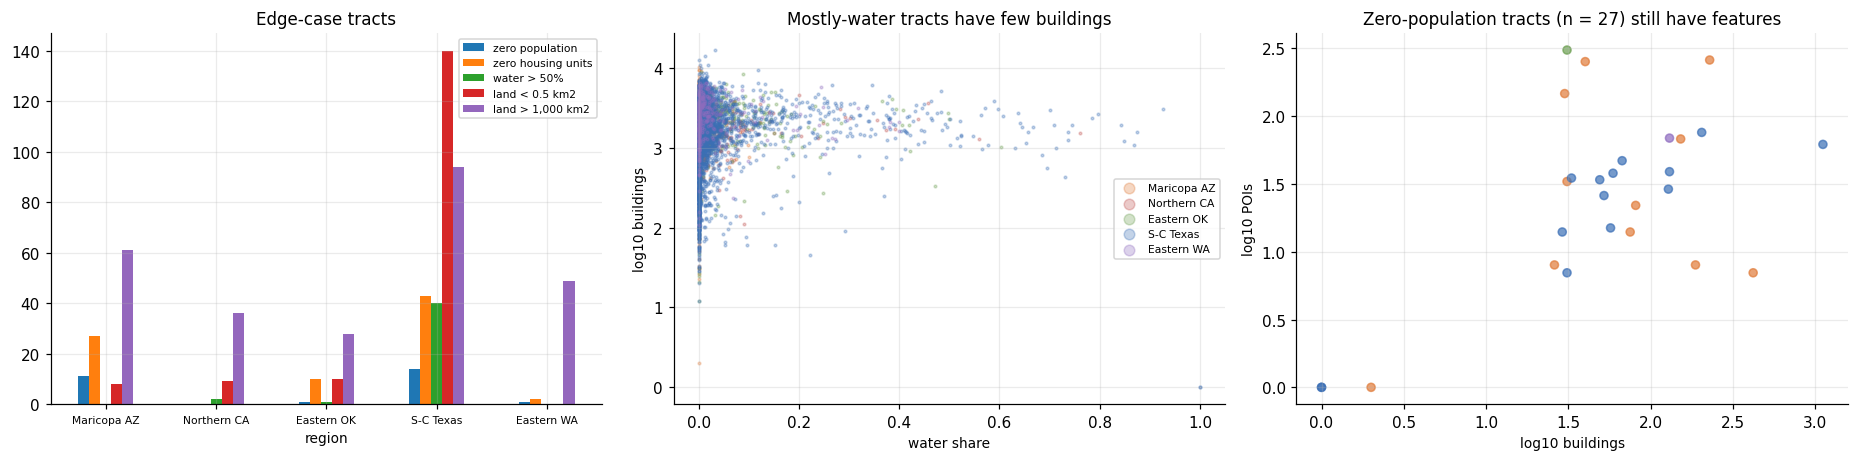

                  zero population  zero housing units  water > 50%  land < 0.5 km2  land > 1,000 km2
region                                                                                              
maricopa-az                    11                  27            0               8                61
northern-ca                     0                   0            2               9                36
eastern-ok                      1                  10            1              10                28
south-central-tx               14                  43           40             140                94
eastern-wa                      1                   2            0               0                49


In [8]:
edge = pd.DataFrame({"zero population": df.groupby("region").pop_total.apply(lambda s: (s == 0).sum()), "zero housing units": df.groupby("region").housing_units.apply(lambda s: (s == 0).sum()),
                     "water > 50%": df.groupby("region").water_share.apply(lambda s: (s > .5).sum()), "land < 0.5 km2": df.groupby("region").land_km2.apply(lambda s: (s < .5).sum()), "land > 1,000 km2": df.groupby("region").land_km2.apply(lambda s: (s > 1000).sum())}).reindex(REG)
z = df[df.pop_total == 0]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
edge.plot.bar(ax=ax[0], rot=0); ax[0].set_xticklabels([NAME[r] for r in REG], fontsize=7); ax[0].set_title("Edge-case tracts"); ax[0].legend(fontsize=7)
for r in REG: d_ = df[df.region == r]; ax[1].scatter(d_.water_share, np.log10(d_.bldg_n.clip(lower=1)), s=3, alpha=.3, color=COL[r], label=NAME[r])
ax[1].set(xlabel="water share", ylabel="log10 buildings", title="Mostly-water tracts have few buildings"); ax[1].legend(markerscale=4, fontsize=7)
ax[2].scatter(np.log10(z.bldg_n.clip(lower=1)), np.log10(z.poi_n.clip(lower=1)), s=28, c=[COL[r] for r in z.region], alpha=.7); ax[2].set(xlabel="log10 buildings", ylabel="log10 POIs", title=f"Zero-population tracts (n = {len(z)}) still have features")
plt.tight_layout(); plt.show(); print(edge.to_string())

**Takeaway:** most edge cases are in Texas (40 mostly-water tracts, 140 tiny ones, 43 with no housing units). Zero-population tracts (parks, airports, bases) still contain buildings and POIs, so a population denominator fails for them and they need explicit handling.